# Non-Homogeneous Linear Difference Equations

As a next step we added deposits and withdrawals to the model, which we denoted by $e_t$ and assumed that the follow a uniform distribution between -5 and 5 but did not try to solve the equation:

:::{.ex-class}
$$
x_{t} = (1 + 0.02) x_{t - 1} + e_t
$$
:::

The difference with the homogeneous equation is the presence of the $e_t$ term.

Our goal for today is to study the behavior (how does the value change over time) of systems described by first order linear difference equations.
First we want to write the equation in a more general form, so we will replace the 1.02 with a parameter $\phi$.

$$
x_{t} = \phi x_{t - 1} + e_t
$$

It will help if we can again solve the equation, that is express $x_t$ as a function of $x_0$, $\phi$, $e_t$ and $t$.
Luckily we can use the same approach as before.

It helps if we write the equation for a couple of periods.

$$
\begin{align}
t & \quad y_t \\
1 & \quad y_1 = \phi y_{0} + e_{1} \\
2 & \quad y_2 = \phi y_{1} + e_{2} \\
3 & \quad y_3 = \phi y_{2} + e_{3} \\
& \vdots \\
t & \quad y_{t} = \phi y_{t - 1} + e_{t} \\
t + 1 &  \quad y_{t + 1} = \phi y_{t} + e_{t + 1}\\
t + 2 & \quad y_{t + 2} = \phi y_{t + 1} + e_{t + 2}
\end{align}
$$

Try substituting the first equation into the second, then the second into the third equation.


::: {.callout-note collapse="true"}
## Click here to see the solution

$$
y_3 = \phi^3 y_0 + \phi^2 e_{1} + \phi e_{2} + \phi^0e_{3}
$$
:::

After that try writing the equation for $y_{t + 1}$ and substituting $y_t$ into it, then substituting $y_{t + 1}$ into the equation for $y_{t + 2}$.
and so forth until you see a pattern. After that generalize the result for $y_{t + j}$.



$$
y_{t + j} = \phi^{j + 1} y_{t - 1} + \phi^{j}e_{t} + \phi^{j - 1} e_{t + 1} + \ldots \phi^1 e_{t + j - 1} + \phi^0 e_{t + j}
$$
We can write this more compactly as:

:::{.ex-class}
$$
y_{t + j} = \phi^{j + 1} y_{t - 1} + \sum_{k = 0}^{j} \phi^{k} e_{t + j - k}
$$
:::

You should check that the above formula is correct. Let's write it down for 
$j = 2$.

::: {.callout-note collapse="true"}
## Click here to see the result

$$
\begin{align}
y_{t + 2} = \phi^{2 + 1}y_{t - 1} & + \phi^0 e_{t + 2 - 0} \\
& + \phi^{1} e_{t + 2 - 1} \\
& + \phi^{2} e_{t + 2 - 2} \\
\end{align}
$$
:::

Now we follow exactly the same logic as before and ask: 

1. What will happen to the value of $y_{t + j}$ as $j$ goes to infinity if we change one of the $e_t$ terms by a small amount?
2. What will happen to the value of $y_{t + j}$ as $j$ goes to infinity if we change all of the $e_t$ terms by a small amount?

As was the case with the initial condition in the homogeneous equation, the answer depends on the value of $\phi$.

The derivative of $y_{t + j}$ with respect to $e_t$ is:

$$
\frac{\partial y_{t + j}}{\partial e_t} = \phi^{j}
$$

So a tiny change in $e_t$ will change $y_{t + j}$ by $\phi^j$ times that tiny change. But we already known what happens to $\phi^j$ as $j$ goes to infinity from our analysis of the homogeneous equation.

- If $|\phi| < 1$ then $\phi^j$ goes to zero as $j$ goes to infinity. So a tiny change in $e_t$ will have no effect on $y_{t + j}$ for large $j$ (meaning after enough time has passed).
- If $|\phi| = 1$ then $\phi^j$ stays constant (meaning the effect of the change in $e_t$ will persist over time).
- If $|\phi| > 1$ then $\phi^j$ diverges (meaning the effect of the change in $e_t$ will get larger and larger over time without bound).


The following plot shows the two different behaviors for $\phi = 0.5$ and $\phi = 1.5$.


In [ ]:
#ex-class

import numpy as np
import matplotlib.pyplot as plt

np.random.seed(41232)

t = np.arange(100)
x_0 = 10

phi = 0.5
shock_t_0 = 10

np.random.seed(12)

e = np.random.uniform(-5, 5, size=len(t))

x = np.zeros((2, len(t)))

for i in range(len(t)):
    if i == 0:
        x[0, i] = x_0 + e[i]
        x[1, i] = x_0 + e[i] + shock_t_0
    else:
        x[0, i] = phi * x[0, i - 1] + e[i]
        x[1, i] = phi * x[1, i - 1] + e[i]


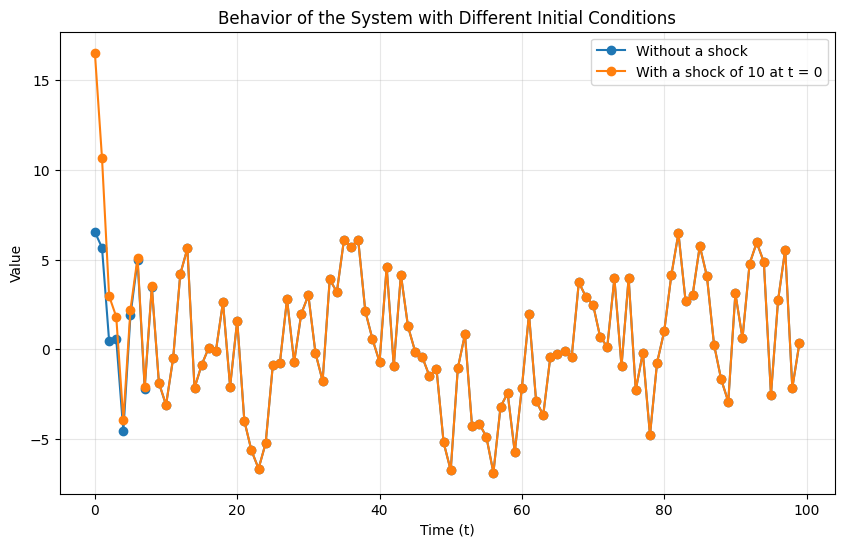

In [ ]:
#ex-class
# Plot the two rows of x

plt.figure(figsize=(10, 6))
plt.plot(t, x[0], label="Without a shock", marker="o")
plt.plot(t, x[1], label=f"With a shock of {shock_t_0} at t = 0", marker="o")
plt.title(r"Behavior of the System with Different Initial Conditions")
plt.xlabel(r"Time (t)")
plt.ylabel(r"Value")
plt.legend()
plt.grid(alpha=0.3)

You will notice that the difference between the two series almost disappears after the 7-th period.

In [ ]:

# You can also inspect the difference directly (here it shows the difference in the first 10 periods)

(x[1] - x[0])[:10]

array([10.        ,  5.        ,  2.5       ,  1.25      ,  0.625     ,
        0.3125    ,  0.15625   ,  0.078125  ,  0.0390625 ,  0.01953125])

Now let's take a look at the effect of changing all of the $e_t$ terms by some amount (for example by adding 10 to each of them).

$$
\begin{align*}
y_{t + j}^{*} & = \phi^{j + 1} y_{t - 1} + \sum_{k = 0}^{j} \phi^{k} (e_{t + j - k} + 10) \\
              & = \phi^{j + 1} y_{t - 1} + \sum_{k = 0}^{j} \phi^{k} e_{t + j - k} + \sum_{k = 0}^{j} 10 \phi^{k} \\
              & = y_{t + j} + 10 \sum_{k = 0}^{j} \phi^{k} \\
\end{align*}
$$

Now the answer boils down to what happens to the sum $\sum_{k = 0}^{j} \phi^{k}$ as $j$ goes to infinity. By the way, you already known this series from basic algebra. It is a geometric series.

:::{#thm-geometric-series}
## Convergence of a Geometric Series

$$
S_{n} = 1 + \phi + \phi^2 + \phi^3 + \ldots + \phi^n
$$

Assuming that $\phi \neq 1$, this series can be expressed more compactly as 

$$
S_{n} = \frac{1 - \phi^{n + 1}}{1 - \phi}
$$

To see this, compute the difference between $S_n$ and $\phi S_n$ and rearrange.

If $|\phi| < 1 \iff -1 < \phi < 1$ the series has a limit for $n \to \infty$:

$$
\lim_{n \to \infty} S_{n} = \frac{1}{1 - \phi}
$$
:::

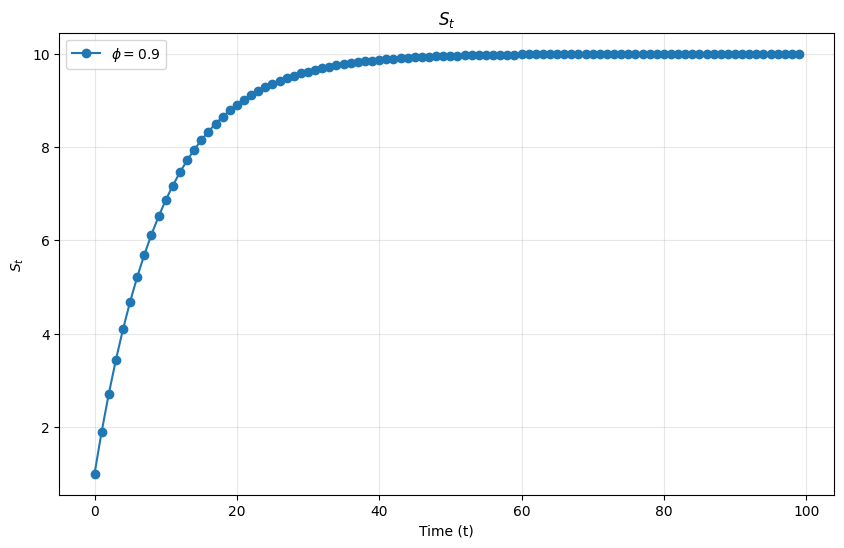

In [11]:
# Let us check it with code

t = np.arange(100)
phi = 0.9

S_t = np.cumsum(phi**t)

plt.figure(figsize=(10, 6))
plt.plot(t, S_t, label=rf"$\phi = {phi}$", marker="o")
plt.title(r"$S_t$")
plt.xlabel(r"Time (t)")
plt.ylabel(r"$S_t$")
plt.legend()
plt.grid(alpha=0.3)